In [1]:
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

from tqdm import tqdm

#changes default of autoreloader to continually reload (2) rather than only on restart
#good for debuggin but does slow code as it is continully reloading modules
%load_ext autoreload
%autoreload 2

#can also use dir() to check what is in function and that new params have been loaded

import os
import glob


desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
mypath = desktop
import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_data
from plots import plot_dsc, cummulative_plot

import data

In [2]:
from pathlib import Path
paths ={}
paths['3wk']={'path' : '//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables/'}
paths['5wk']={'path' : '//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/'}

STEDdata={}
for dataset, d in paths.items():
    print('STEDdata'+'-'+dataset) 
    
    path_to_data=d['path']
    STEDdata[dataset]={}
    
    for File in glob.glob(path_to_data+"*Local*"):
        print(File)
        name = Path(File).name
        dendrite = 'dendrite'+name.split(' - ')[0]
        
        STEDdata[dataset][dendrite] = {'path':File} 
        STEDdata[dataset][dendrite]['file']= name
        STEDdata[dataset][dendrite]['ex_factor'] = 1
        STEDdata[dataset][dendrite]['res'] = 0.04


STEDdata-3wk
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\16 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\17 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\21 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\25 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\25-2 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\27 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\28 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite

In [3]:
for n, dataSet in STEDdata.items():
    #print(name, data)
    
    for name, dendrite in dataSet.items():
        print(name)
        
        #print(data[name]['path'])
        file_path = dendrite['path']#+dendrite['file']
        dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])
    
    #plot_dsc(dataSet)

dendrite16
dendrite17
dendrite21
dendrite25
dendrite25-2
dendrite27
dendrite28
dendrite29
dendrite29-4
dendrite30
dendrite31
dendrite33-1
dendrite33-2
dendrite35-0
dendrite36-0
dendrite36-1
dendrite36-2
dendrite36-3
dendrite37
dendrite38
dendrite39-1
dendrite39-21
dendrite39-22
dendrite40-1
dendrite40-4
dendrite41-0
dendrite43
dendrite53
dendrite55
dendrite14
dendrite20
dendrite25-0
dendrite26
dendrite27
dendrite31
dendrite32
dendrite33
dendrite35-1
dendrite36-1
dendrite36-2
dendrite38-1
dendrite40
dendrite41-2
dendrite42-2
dendrite43-1
dendrite43-2
dendrite45-2
dendrite50
dendrite52
dendrite55


In [ ]:
dataSet=STEDdata['5wk']
name='dendrite38-1'

#plot_dsc(dataSet)

file_path = dataSet[name]['path']
dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])
    



analyse frames in data dic

In [4]:
###3wks
#manually add/remove DSCs
branch = STEDdata['3wk']['dendrite25']
del branch['DSCs'][0]
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)


branch = STEDdata['3wk']['dendrite28']
#branch['DSCs'].pop[0] 
del branch['DSCs'][0]
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['3wk']['dendrite29-4']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['3wk']['dendrite39-21']
del branch['DSCs'][2]
update_DSCs(branch)
update_compartments(branch)


branch = STEDdata['3wk']['dendrite40-4'] #update DSC properties
DSC= branch['DSCs'][0]
branch['DSC_properties'][0]['mean'] = DSC.smth[37:47].mean()
branch['DSC_properties'][0]['length'] = DSC.length[DSC.length.index[0]+47]-DSC.length[DSC.length.index[0]+37]

branch = STEDdata['3wk']['dendrite41-0']
del branch['DSCs'][1]
update_DSCs(branch)
update_compartments(branch)

###5wks
#manually add/remove DSCs
branch = STEDdata['5wk']['dendrite36-2']
DSC=branch['data'][145:270].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite38-1'] #update DSC properties missing end upswing
DSC= branch['DSCs'][0]
branch['DSC_properties'][0]['mean'] = DSC.smth[11:32].mean()
branch['DSC_properties'][0]['length'] = DSC.length[DSC.length.index[0]+32]-DSC.length[DSC.length.index[0]+11]

#manually add/remove DSCs
branch = STEDdata['5wk']['dendrite42-2']
DSC=branch['data'][50:150].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite14']
del branch['DSCs'][3]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite43-1']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite43-2']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite55']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)


plot the individual dendrites with each DSC highlited in a different colour

In [ ]:
plot_dsc(STEDdata['5wk'])

get summary stats

get mean of all DSCs across all dendrites

c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\anaconda3\Lib\site-packages\matplotlib\axes\_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
c:\anaconda3\Lib\site-packages\matplotlib\axes\_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])
c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:226: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:

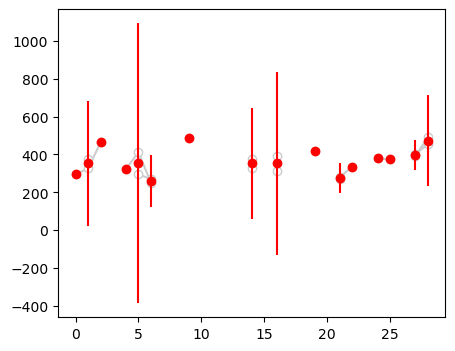

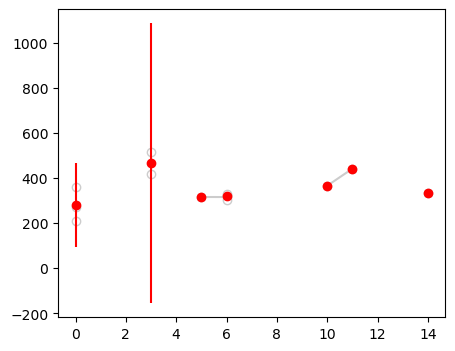

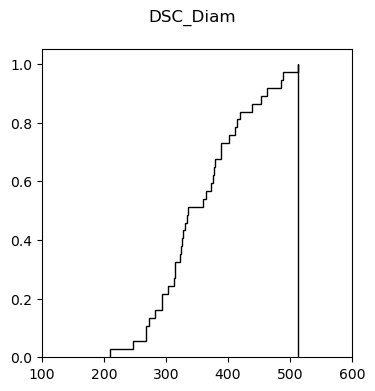

In [11]:
df3= summary_data(STEDdata['3wk'], 'mean')
df5= summary_data(STEDdata['5wk'], 'mean')

df = pd.concat([df3, df5])

fig, ax = plt.subplots(figsize=(4, 4))
n_bins=200
fig.suptitle("DSC_Diam")
## plot the cumulative histogra
#n, bins, patches = ax.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)

#get average line 
df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='black', density=True, histtype='step', cumulative=True)
ax.set_xlim([100,600])

fig.savefig('C:/Users/Tony Kelly/Desktop/DSC_Cumulative.svg', bbox_inches = 'tight')

In [8]:
print(df.mean())
print(df.sem())


2.8495446486486493
0.29802515401275226


In [ ]:
fig, ax = cummulative_plot(STEDdata)

ax.set_xlim([0,1000])
